In [1]:
import batman
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('default')
from dataclasses import replace
import batman_utils
from astro_utils import *
from hyperillumination_phasecurve_utils import *
from paper_plot_utils import paper_figure, paper_theme


In [2]:
# ARBITRARY PLANETARY PARAMETERS

period=1.                                   #orbital period
rp = 0.1                                    #planet radius (in units of stellar radii)
rs = 1                                      #stellar radius (in units of solar radii)
a = 5.                                      #semi-major axis [stellar radii]
a_AU = a*rs*6.957e8/1.495978707e11          #semi-major axis [AU]
incl = 89.                                  #orbital inclination (in degrees)
ecc = 0.2                                   #eccentricity
w = 0.                                      #longitude of periastron (in degrees)
fp = 0.001                                  #planet-to-star flux ratio / occultation depth (integrated day-side flux Fp/Fs(alpha=0))

u = [0.1, 0.3]                              # Stellar limb darkening coefficients [u1, u2] (placeholders, not from K2-141 data, will be set by theoretical stellar atmosphere models)

t = np.linspace(-period/4, period*3/4, 10000)

In [3]:
# Define Exoplanet Object
planet = PlanetParams(name=None, period=period, incl=incl, ecc=ecc, w=w, r1=rp, r2=1., R=a, T2_eff=None, a_AU=a_AU, T14=None)

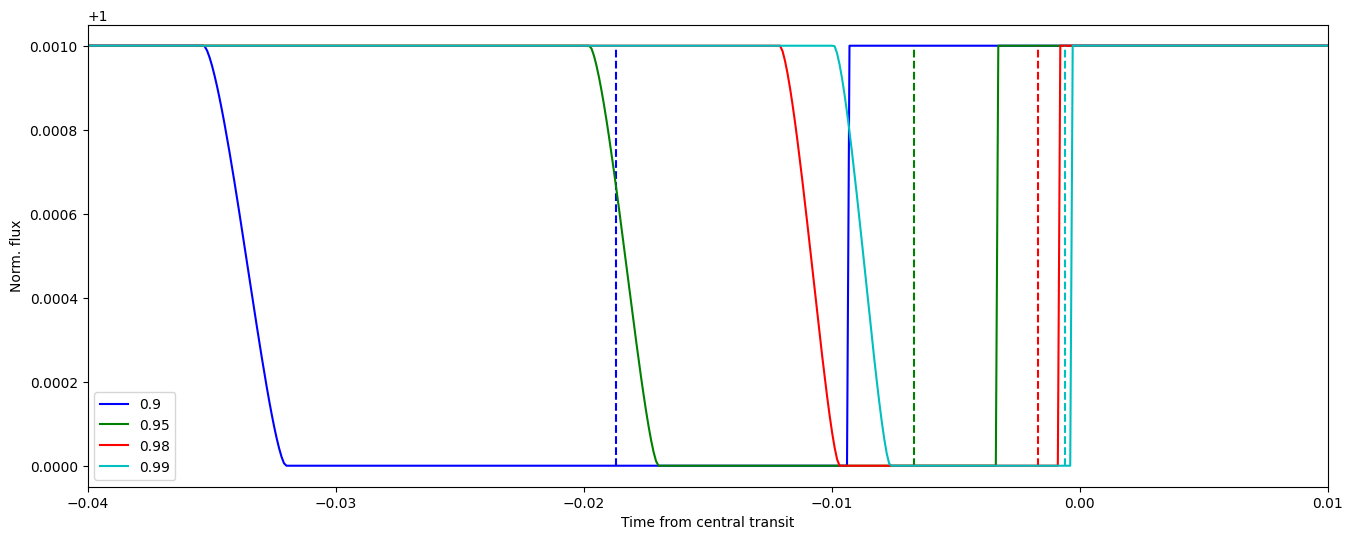

In [4]:
PAPER_MODE = False
w1=0.
plt.figure(figsize=(16, 6))
colors = ['b', 'g', 'r', 'c', 'k']
for i, ecc1 in enumerate([0.9, 0.95, 0.98, 0.99]):
    flux=batman_utils.flux_occultation(replace(planet, ecc=ecc1, w=w1), fp, t)
    plt.plot(t, flux, label=ecc1, color=colors[i])
    plt.vlines(occultation_time(period, ecc1, w1)-1, ymin=flux.min(), ymax=flux.max(), color=colors[i], linestyles='dashed')
plt.xlabel("Time from central transit")
plt.xlim([-period*0.04, period*0.01])
plt.ylabel("Norm. flux")
plt.legend()
paper_figure(f"batman_occultation_ecc_w{w1:g}_high", PAPER_MODE)
plt.show()

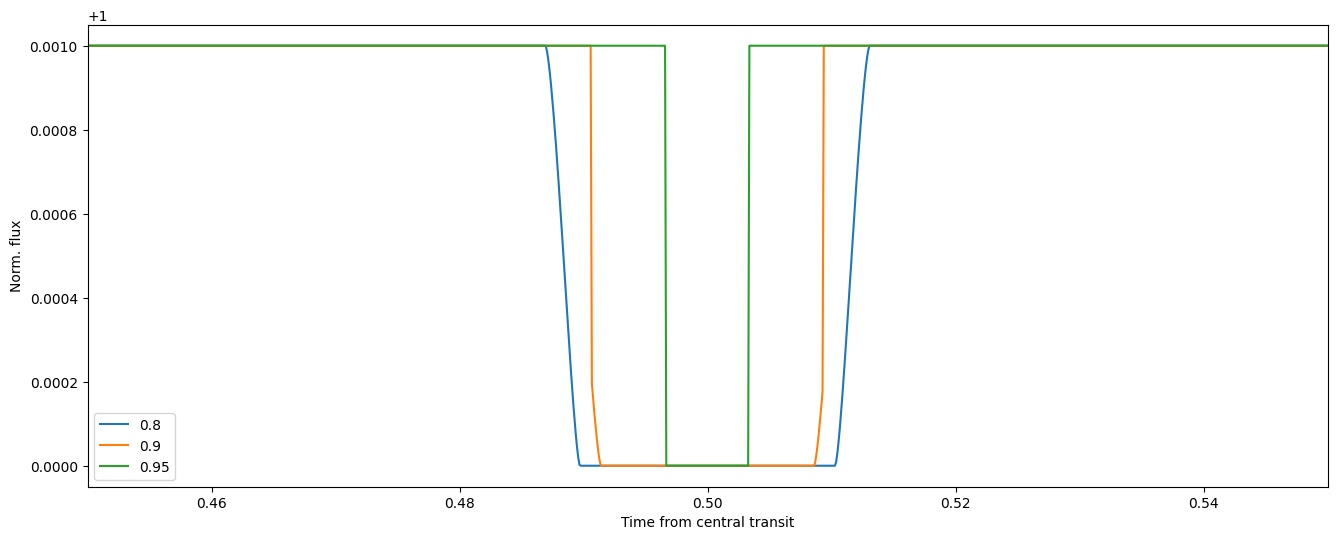

In [5]:
PAPER_MODE = False
w1=270.
plt.figure(figsize=(16, 6))
for ecc1 in [0.8, 0.9, 0.95]:
    plt.plot(t, batman_utils.flux_occultation(replace(planet, ecc=ecc1, w=w1), fp, t), label=ecc1)
plt.xlabel("Time from central transit")
plt.xlim([period*0.45, period*0.55])
plt.ylabel("Norm. flux")
plt.legend()
paper_figure(f"batman_occultation_ecc_w{w1:g}", PAPER_MODE)
plt.show()

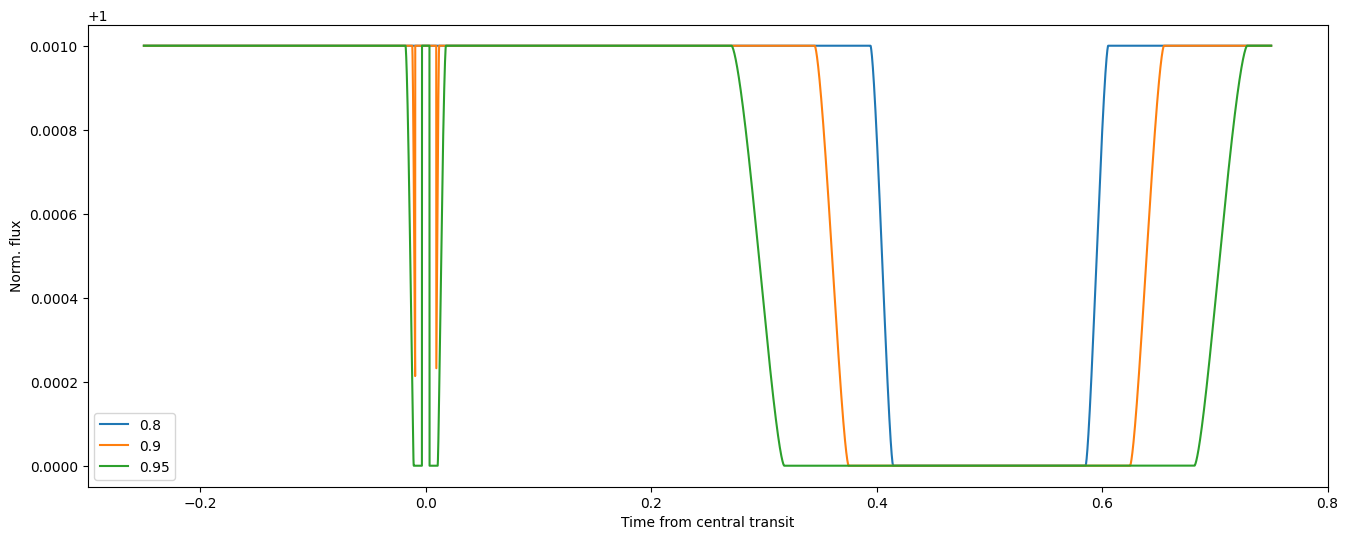

In [6]:
PAPER_MODE = False
w1=90.
plt.figure(figsize=(16, 6))
for ecc1 in [0.8, 0.9, 0.95]:
    plt.plot(t, batman_utils.flux_occultation(replace(planet, ecc=ecc1, w=w1), fp, t), label=ecc1)
plt.xlabel("Time from central transit")
#plt.xlim([period*0.4, period*0.6])
plt.ylabel("Norm. flux")
plt.legend()
paper_figure(f"batman_occultation_ecc_w{w1:g}", PAPER_MODE)
plt.show()

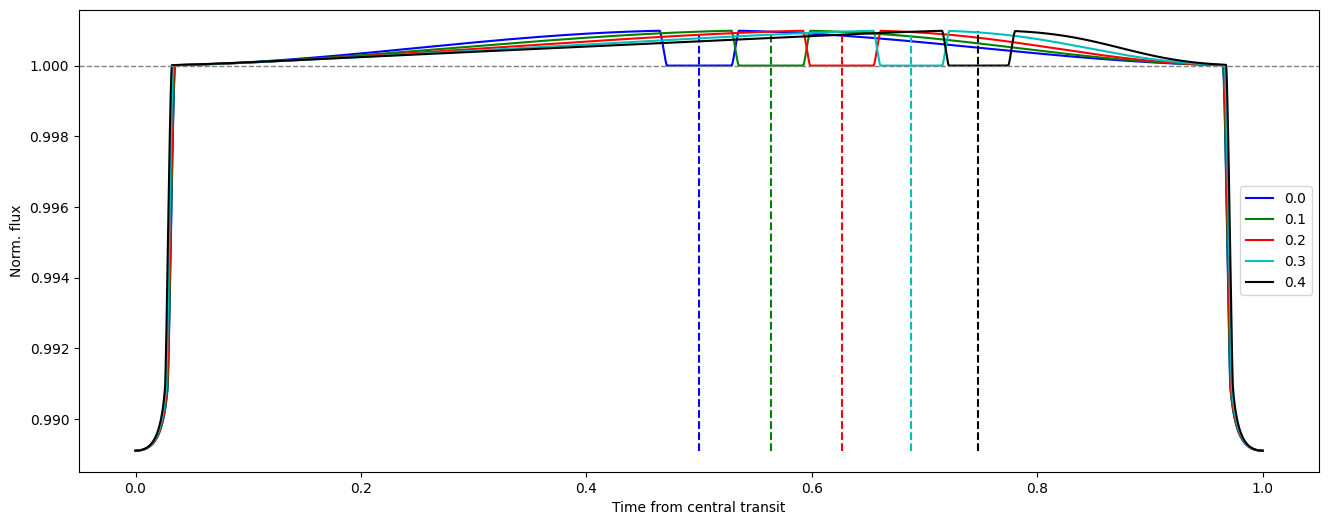

In [7]:
PAPER_MODE = False
w1=0.
plt.figure(figsize=(16, 6))
colors = ['b', 'g', 'r', 'c', 'k']
for i, ecc1 in enumerate([0.0, 0.1, 0.2, 0.3, 0.4]):
    t1, flux1 = batman_utils.Cosine_PhaseCurve(replace(planet, ecc=ecc1, w=w1), fp, t=np.linspace(0, period, 10000), u=u)
    plt.plot(t1, flux1, label=ecc1, color=colors[i])
    plt.vlines(batman_utils.occultation_time(period, ecc1, w1), ymin=flux1.min(), ymax=flux1.max(), color=colors[i], linestyles='dashed')
stellar_flux_line(y=1)
plt.xlabel("Time from central transit")
#plt.xlim([period*0.4, period*0.6])
plt.ylabel("Norm. flux")
plt.legend()
paper_figure(f"batman_cosine_phasecurve_ecc_w{w1:g}", PAPER_MODE)
plt.show()